<a href="https://colab.research.google.com/github/betulcelik1/NLP_Project/blob/main/notebooks/01_TFIDF_LogisticRegression_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/betulcelik1/NLP_Project.git

Cloning into 'NLP_Project'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 12 (delta 0), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (12/12), 43.11 KiB | 2.16 MiB/s, done.


In [2]:
!git clone https://github.com/ilopezgazpio/SemEval-2027-Task-2-DiCo-NLI.git

Cloning into 'SemEval-2027-Task-2-DiCo-NLI'...
remote: Enumerating objects: 524, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 524 (delta 48), reused 47 (delta 44), pack-reused 471 (from 1)
Receiving objects: 100% (524/524), 29.86 MiB | 24.96 MiB/s, done.
Resolving deltas: 100% (271/271), done.


In [3]:
!ls /content

NLP_Project  sample_data  SemEval-2027-Task-2-DiCo-NLI


In [4]:
!find /content/SemEval-2027-Task-2-DiCo-NLI -type f | grep participant_labeled

/content/SemEval-2027-Task-2-DiCo-NLI/final_data/dev/dico_nli_dev_track2_participant_labeled.csv
/content/SemEval-2027-Task-2-DiCo-NLI/final_data/dev/dico_nli_dev_track3_participant_labeled.csv
/content/SemEval-2027-Task-2-DiCo-NLI/final_data/dev/dico_nli_dev_track1_participant_labeled.csv
/content/SemEval-2027-Task-2-DiCo-NLI/final_data/dev/dico_nli_dev_track4_participant_labeled.csv
/content/SemEval-2027-Task-2-DiCo-NLI/final_data/train/dico_nli_train_track1_participant_labeled.csv
/content/SemEval-2027-Task-2-DiCo-NLI/final_data/train/dico_nli_train_track2_participant_labeled.csv
/content/SemEval-2027-Task-2-DiCo-NLI/final_data/train/dico_nli_train_track4_participant_labeled.csv
/content/SemEval-2027-Task-2-DiCo-NLI/final_data/train/dico_nli_train_track3_participant_labeled.csv
/content/SemEval-2027-Task-2-DiCo-NLI/trial_data/dico_nli_trial_track3_participant_labeled.csv
/content/SemEval-2027-Task-2-DiCo-NLI/trial_data/dico_nli_trial_track2_participant_labeled.csv
/content/SemEval-2

In [5]:
import pandas as pd

In [6]:
train_path = "/content/SemEval-2027-Task-2-DiCo-NLI/final_data/train/dico_nli_train_track1_participant_labeled.csv"

dev_path = "/content/SemEval-2027-Task-2-DiCo-NLI/final_data/dev/dico_nli_dev_track1_participant_labeled.csv"

train_df = pd.read_csv(train_path)
dev_df = pd.read_csv(dev_path)

print("Train:", train_df.shape)
print("Dev:", dev_df.shape)

Train: (3042, 7)
Dev: (660, 7)


In [7]:
print("Train columns:")
print(train_df.columns.tolist())

print("\nDev columns:")
print(dev_df.columns.tolist())

Train columns:
['instance_id', 'pair_id', 'text1_lang', 'text2_lang', 'text1', 'text2', 'label']

Dev columns:
['instance_id', 'pair_id', 'text1_lang', 'text2_lang', 'text1', 'text2', 'label']


In [8]:
display(train_df.head())

,instance_id,pair_id,text1_lang,text2_lang,text1,text2,label
0,dico_phrasis_0000001__en-en__flipped,dico_phrasis_0000001,en,en,Conservative opposition,Conservatives,FORWARD_ENTAILMENT
1,dico_phrasis_0000001__en-en__original,dico_phrasis_0000001,en,en,Conservatives,Conservative opposition,BACKWARD_ENTAILMENT
2,dico_phrasis_0000003__en-en__flipped,dico_phrasis_0000003,en,en,Japanese PM Shinzo Abe,Abe,FORWARD_ENTAILMENT
3,dico_phrasis_0000003__en-en__original,dico_phrasis_0000003,en,en,Abe,Japanese PM Shinzo Abe,BACKWARD_ENTAILMENT
4,dico_phrasis_0000005__en-en__flipped,dico_phrasis_0000005,en,en,ballistic missiles,missiles,FORWARD_ENTAILMENT


In [9]:
print(train_df.info())

print("\nMissing values:")
print(train_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3042 entries, 0 to 3041
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   instance_id  3042 non-null   object
 1   pair_id      3042 non-null   object
 2   text1_lang   3042 non-null   object
 3   text2_lang   3042 non-null   object
 4   text1        3042 non-null   object
 5   text2        3042 non-null   object
 6   label        3042 non-null   object
dtypes: object(7)
memory usage: 166.5+ KB
None

Missing values:
instance_id    0
pair_id        0
text1_lang     0
text2_lang     0
text1          0
text2          0
label          0
dtype: int64


In [10]:
print("Train label distribution:")
print(train_df["label"].value_counts())

print("\nTrain label distribution (percentage):")
print((train_df["label"].value_counts(normalize=True) * 100).round(2))

print("\nDev label distribution:")
print(dev_df["label"].value_counts())

Train label distribution:
label
FORWARD_ENTAILMENT     881
BACKWARD_ENTAILMENT    881
EQUIVALENCE            802
NEGATIVE_OTHER         478
Name: count, dtype: int64

Train label distribution (percentage):
label
FORWARD_ENTAILMENT     28.96
BACKWARD_ENTAILMENT    28.96
EQUIVALENCE            26.36
NEGATIVE_OTHER         15.71
Name: proportion, dtype: float64

Dev label distribution:
label
FORWARD_ENTAILMENT     190
BACKWARD_ENTAILMENT    190
EQUIVALENCE            174
NEGATIVE_OTHER         106
Name: count, dtype: int64


In [11]:
for i in range(5):
    print(f"\n--- Example {i+1} ---")
    print("Text 1:", train_df.loc[i, "text1"])
    print("Text 2:", train_df.loc[i, "text2"])
    print("Label:", train_df.loc[i, "label"])


--- Example 1 ---
Text 1: Conservative opposition
Text 2: Conservatives
Label: FORWARD_ENTAILMENT

--- Example 2 ---
Text 1: Conservatives
Text 2: Conservative opposition
Label: BACKWARD_ENTAILMENT

--- Example 3 ---
Text 1: Japanese PM Shinzo Abe
Text 2: Abe
Label: FORWARD_ENTAILMENT

--- Example 4 ---
Text 1: Abe
Text 2: Japanese PM Shinzo Abe
Label: BACKWARD_ENTAILMENT

--- Example 5 ---
Text 1: ballistic missiles
Text 2: missiles
Label: FORWARD_ENTAILMENT


In [12]:
train_texts = (
    "Text1: " + train_df["text1"].astype(str) +
    " Text2: " + train_df["text2"].astype(str)
)

dev_texts = (
    "Text1: " + dev_df["text1"].astype(str) +
    " Text2: " + dev_df["text2"].astype(str)
)

y_train = train_df["label"]
y_dev = dev_df["label"]

print(train_texts.iloc[0])
print("\nLabel:", y_train.iloc[0])

Text1: Conservative opposition Text2: Conservatives

Label: FORWARD_ENTAILMENT


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=50000
)

X_train = tfidf.fit_transform(train_texts)
X_dev = tfidf.transform(dev_texts)

print("Train feature matrix:", X_train.shape)
print("Dev feature matrix:", X_dev.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Train feature matrix: (3042, 8847)
Dev feature matrix: (660, 8847)
Vocabulary size: 8847


In [14]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [15]:
y_pred = lr_model.predict(X_dev)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
['FORWARD_ENTAILMENT' 'BACKWARD_ENTAILMENT' 'NEGATIVE_OTHER'
 'NEGATIVE_OTHER' 'EQUIVALENCE' 'EQUIVALENCE' 'FORWARD_ENTAILMENT'
 'BACKWARD_ENTAILMENT' 'FORWARD_ENTAILMENT' 'BACKWARD_ENTAILMENT']


In [16]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_dev, y_pred)
macro_f1 = f1_score(y_dev, y_pred, average="macro")
weighted_f1 = f1_score(y_dev, y_pred, average="weighted")

print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))
print("Weighted F1:", round(weighted_f1, 4))

print("\nClassification Report:")
print(classification_report(y_dev, y_pred))

Accuracy: 0.45
Macro F1: 0.4449
Weighted F1: 0.4612

Classification Report:
                     precision    recall  f1-score   support

BACKWARD_ENTAILMENT       0.56      0.44      0.50       190
        EQUIVALENCE       0.49      0.45      0.47       174
 FORWARD_ENTAILMENT       0.54      0.47      0.50       190
     NEGATIVE_OTHER       0.24      0.43      0.31       106

           accuracy                           0.45       660
          macro avg       0.46      0.45      0.44       660
       weighted avg       0.49      0.45      0.46       660



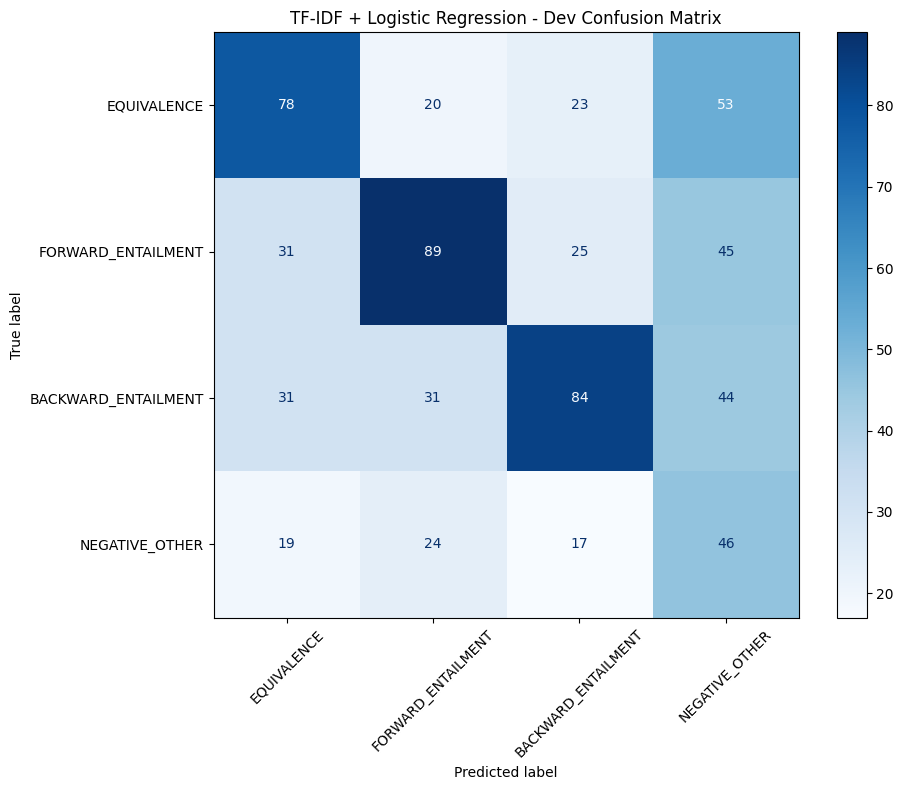

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

labels = [
    "EQUIVALENCE",
    "FORWARD_ENTAILMENT",
    "BACKWARD_ENTAILMENT",
    "NEGATIVE_OTHER"
]

cm = confusion_matrix(y_dev, y_pred, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("TF-IDF + Logistic Regression - Dev Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
import pandas as pd

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

print(cm_df)

                     EQUIVALENCE  FORWARD_ENTAILMENT  BACKWARD_ENTAILMENT  \
EQUIVALENCE                   78                  20                   23   
FORWARD_ENTAILMENT            31                  89                   25   
BACKWARD_ENTAILMENT           31                  31                   84   
NEGATIVE_OTHER                19                  24                   17   

                     NEGATIVE_OTHER  
EQUIVALENCE                      53  
FORWARD_ENTAILMENT               45  
BACKWARD_ENTAILMENT              44  
NEGATIVE_OTHER                   46  


In [19]:
error_df = dev_df.copy()

error_df["predicted_label"] = y_pred
error_df["correct"] = error_df["label"] == error_df["predicted_label"]

wrong_predictions = error_df[error_df["correct"] == False].copy()

print("Total incorrect predictions:", len(wrong_predictions))
print("Total correct predictions:", (error_df["correct"]).sum())

display(
    wrong_predictions[
        ["text1", "text2", "label", "predicted_label"]
    ].head(20)
)

Total incorrect predictions: 363
Total correct predictions: 297


,text1,text2,label,predicted_label
2,anti-protest laws,anti-protest law,FORWARD_ENTAILMENT,NEGATIVE_OTHER
3,anti-protest law,anti-protest laws,BACKWARD_ENTAILMENT,NEGATIVE_OTHER
4,Iran nuclear experts and also world powers,World powers and Iran,FORWARD_ENTAILMENT,EQUIVALENCE
5,World powers and Iran,Iran nuclear experts and also world powers,BACKWARD_ENTAILMENT,EQUIVALENCE
10,Security video,Video,FORWARD_ENTAILMENT,NEGATIVE_OTHER
11,Video,Security video,BACKWARD_ENTAILMENT,NEGATIVE_OTHER
14,Pope Francis,pope,FORWARD_ENTAILMENT,EQUIVALENCE
15,pope,Pope Francis,BACKWARD_ENTAILMENT,EQUIVALENCE
17,destroy,in destroying,BACKWARD_ENTAILMENT,NEGATIVE_OTHER
19,Bradley Manning,Wikileaks soldier Bradley Manning,BACKWARD_ENTAILMENT,FORWARD_ENTAILMENT


In [20]:
wrong_predictions["error_type"] = (
    wrong_predictions["label"] + " -> " +
    wrong_predictions["predicted_label"]
)

print(wrong_predictions["error_type"].value_counts())

error_type
EQUIVALENCE -> NEGATIVE_OTHER                53
FORWARD_ENTAILMENT -> NEGATIVE_OTHER         45
BACKWARD_ENTAILMENT -> NEGATIVE_OTHER        44
FORWARD_ENTAILMENT -> EQUIVALENCE            31
BACKWARD_ENTAILMENT -> EQUIVALENCE           31
BACKWARD_ENTAILMENT -> FORWARD_ENTAILMENT    31
FORWARD_ENTAILMENT -> BACKWARD_ENTAILMENT    25
NEGATIVE_OTHER -> FORWARD_ENTAILMENT         24
EQUIVALENCE -> BACKWARD_ENTAILMENT           23
EQUIVALENCE -> FORWARD_ENTAILMENT            20
NEGATIVE_OTHER -> EQUIVALENCE                19
NEGATIVE_OTHER -> BACKWARD_ENTAILMENT        17
Name: count, dtype: int64


In [21]:
import json
import os

results_dir = "/content/NLP_Project/results/baseline"
os.makedirs(results_dir, exist_ok=True)

baseline_metrics = {
    "model": "TF-IDF + Logistic Regression",
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "train_size": int(len(train_df)),
    "dev_size": int(len(dev_df)),
    "vocabulary_size": int(len(tfidf.vocabulary_)),
    "ngram_range": [1, 2],
    "max_features": 50000,
    "class_weight": "balanced"
}

with open(
    os.path.join(results_dir, "metrics.json"),
    "w"
) as f:
    json.dump(baseline_metrics, f, indent=4)

print("Metrics saved.")

Metrics saved.


In [22]:
predictions_df = pd.DataFrame({
    "instance_id": dev_df["instance_id"],
    "pair_id": dev_df["pair_id"],
    "text1": dev_df["text1"],
    "text2": dev_df["text2"],
    "true_label": y_dev,
    "predicted_label": y_pred
})

predictions_df.to_csv(
    os.path.join(results_dir, "dev_predictions.csv"),
    index=False
)

print("Predictions saved.")

Predictions saved.


In [23]:
pair_analysis = dev_df.copy()

pair_analysis["predicted_label"] = y_pred

pair_sizes = pair_analysis.groupby("pair_id").size()

print("Pair size distribution:")
print(pair_sizes.value_counts())

Pair size distribution:
2    277
1    106
Name: count, dtype: int64


In [24]:
paired_ids = pair_sizes[pair_sizes == 2].index

paired_df = pair_analysis[
    pair_analysis["pair_id"].isin(paired_ids)
].sort_values("pair_id")

display(
    paired_df[
        ["pair_id", "text1", "text2", "label", "predicted_label"]
    ].head(20)
)

,pair_id,text1,text2,label,predicted_label
0,dico_phrasis_0000002,'s war shrine visit,'s shrine visit,FORWARD_ENTAILMENT,FORWARD_ENTAILMENT
1,dico_phrasis_0000002,'s shrine visit,'s war shrine visit,BACKWARD_ENTAILMENT,BACKWARD_ENTAILMENT
2,dico_phrasis_0000004,anti-protest laws,anti-protest law,FORWARD_ENTAILMENT,NEGATIVE_OTHER
3,dico_phrasis_0000004,anti-protest law,anti-protest laws,BACKWARD_ENTAILMENT,NEGATIVE_OTHER
4,dico_phrasis_0000008,Iran nuclear experts and also world powers,World powers and Iran,FORWARD_ENTAILMENT,EQUIVALENCE
5,dico_phrasis_0000008,World powers and Iran,Iran nuclear experts and also world powers,BACKWARD_ENTAILMENT,EQUIVALENCE
6,dico_phrasis_0000010,Nine children,Five children,FORWARD_ENTAILMENT,FORWARD_ENTAILMENT
7,dico_phrasis_0000010,Five children,Nine children,BACKWARD_ENTAILMENT,BACKWARD_ENTAILMENT
8,dico_phrasis_0000018,of all Rage rallies,march of anger,FORWARD_ENTAILMENT,FORWARD_ENTAILMENT
9,dico_phrasis_0000018,march of anger,of all Rage rallies,BACKWARD_ENTAILMENT,BACKWARD_ENTAILMENT


In [25]:
pair_eval = dev_df.copy()

pair_eval["predicted_label"] = y_pred
pair_eval["is_correct"] = pair_eval["label"] == pair_eval["predicted_label"]

paired_eval = pair_eval.groupby("pair_id").filter(
    lambda group: len(group) == 2
)

pair_results = []

for pair_id, group in paired_eval.groupby("pair_id"):
    correct_count = group["is_correct"].sum()

    if correct_count == 2:
        status = "Both correct"
    elif correct_count == 1:
        status = "One correct"
    else:
        status = "Both incorrect"

    pair_results.append({
        "pair_id": pair_id,
        "status": status,
        "correct_count": correct_count
    })

pair_results_df = pd.DataFrame(pair_results)

print(pair_results_df["status"].value_counts())

print("\nPair-level accuracy:")
print(
    round(
        pair_results_df["correct_count"].sum() /
        (len(pair_results_df) * 2),
        4
    )
)

status
Both incorrect    131
Both correct      105
One correct        41
Name: count, dtype: int64

Pair-level accuracy:
0.4531


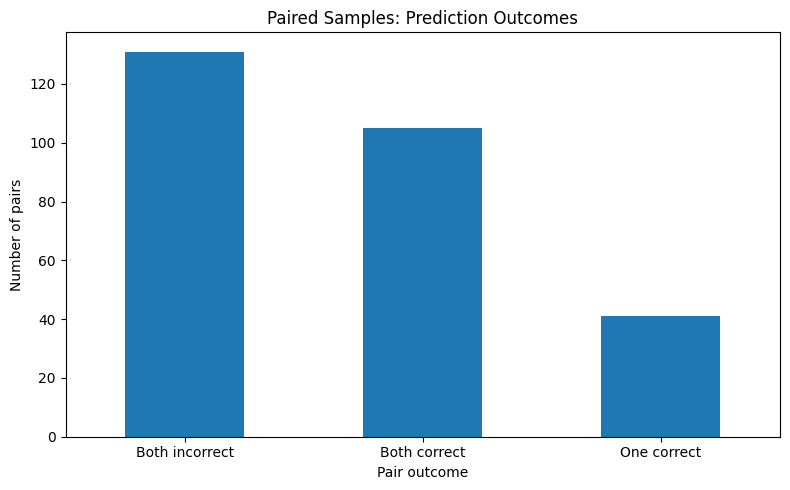

In [26]:
import matplotlib.pyplot as plt

pair_status_counts = pair_results_df["status"].value_counts()

plt.figure(figsize=(8, 5))
pair_status_counts.plot(kind="bar")
plt.title("Paired Samples: Prediction Outcomes")
plt.ylabel("Number of pairs")
plt.xlabel("Pair outcome")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
error_analysis_path = os.path.join(
    results_dir,
    "error_analysis.csv"
)

wrong_predictions.to_csv(
    error_analysis_path,
    index=False
)

print("Error analysis saved:", error_analysis_path)

Error analysis saved: /content/NLP_Project/results/baseline/error_analysis.csv
